# Tahap 3–4: Evaluasi Lanjutan dan Finalisasi Model Tipat

**Notebook pendamping** `Perbandingan_MobileNetV2_EfficientNetB0_ResNet50_Tipat.ipynb`.

Notebook ini **tidak melatih ulang** ketiga arsitektur. Ia memuat hasil split, model `.keras`, dan CSV yang telah disimpan oleh notebook sebelumnya.

**Alur:** (3A) memuat hasil → (3B) evaluasi prediksi salah/benar → (3C) cek duplikasi → (3D) evaluasi transfer vs fine-tuning pada validation → (3E) riwayat grafik jika ada → (3F) uji foto eksternal → (4A) pemilihan kandidat → (4B) ekspor dan uji pemuatan model.

**Sebelum menjalankan:** pastikan notebook awal sudah pernah dijalankan sampai selesai dan file model serta folder split masih tersedia. Ubah `PROJECT_PARENT` di sel konfigurasi. **Jangan menjalankan sel split pada notebook lama lagi** jika hanya ingin melanjutkan analisis. 

## 3A. Impor dan konfigurasi proyek

In [15]:
from pathlib import Path
import json, shutil, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
import tensorflow as tf
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from IPython.display import display

# UBAH lokasi ini agar sesuai dengan direktori induk folder Tipat kamu.
PROJECT_PARENT = Path(r"C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING")
SPLIT_DIR = PROJECT_PARENT / "Tipat_Compare_Preprocessed"
MODEL_DIR = PROJECT_PARENT / "Tipat_Compare_Models"
RESULT_DIR = PROJECT_PARENT / "Hasil_Perbandingan_Tipat"
STAGE34_DIR = RESULT_DIR / "Tahap_3_4"
STAGE34_DIR.mkdir(parents=True, exist_ok=True)
MODEL_NAMES = ["MobileNetV2", "EfficientNetB0", "ResNet50"]
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42
PREPROCESSORS = {
    "MobileNetV2": tf.keras.applications.mobilenet_v2.preprocess_input,
    "EfficientNetB0": tf.keras.applications.efficientnet.preprocess_input,
    "ResNet50": tf.keras.applications.resnet50.preprocess_input,
}
CLASS_FILE = RESULT_DIR / "class_names.json"
if not CLASS_FILE.is_file():
    raise FileNotFoundError(f"Kelas tidak ditemukan: {CLASS_FILE}. Jalankan notebook awal hingga selesai.")
class_names = json.loads(CLASS_FILE.read_text(encoding="utf-8"))
for p in [SPLIT_DIR / "validation", SPLIT_DIR / "test"]:
    if not p.is_dir():
        raise FileNotFoundError(f"Folder split hilang: {p}")
for name in MODEL_NAMES:
    f = MODEL_DIR / f"{name.lower()}_fine_tuned.keras"
    if not f.is_file():
        raise FileNotFoundError(f"Model fine-tuned tidak ditemukan: {f}")
print("Versi TensorFlow:", tf.__version__)
print("Kelas:", class_names)
print("Output tambahan:", STAGE34_DIR)

Versi TensorFlow: 2.15.1
Kelas: ['Tipat Dampulan', 'Tipat Gatep', 'Tipat Gong', 'Tipat Kukur', 'Tipat Lepet', 'Tipat Nasi', 'Tipat Pengambean', 'Tipat Sari', 'Tipat Sirikan', 'Tipat Taluh']
Output tambahan: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Hasil_Perbandingan_Tipat\Tahap_3_4


## 3B. Analisis contoh prediksi benar dan salah pada test set

Gunakan model yang sudah tersimpan dan **test set yang sama** dari eksperimen awal. Foto ditampilkan beserta ground truth, prediksi, dan confidence. Ini adalah *audit* atas hasil pengujian terdahulu, bukan test set baru.

In [16]:
def image_files_and_labels(split_name):
    root = SPLIT_DIR / split_name
    paths, labels = [], []
    for index, class_name in enumerate(class_names):
        class_dir = root / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(class_dir)
        for path in sorted(class_dir.iterdir()):
            if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                paths.append(path)
                labels.append(index)
    return paths, np.array(labels, dtype=int)

def predict_files(model, files, model_name):
    """Cocokkan preprocessing dan ukuran gambar dengan eksperimen awal."""
    results = []
    preprocess = PREPROCESSORS[model_name]
    for start in range(0, len(files), BATCH_SIZE):
        batch = files[start:start+BATCH_SIZE]
        arrays = []
        for path in batch:
            with Image.open(path) as img:
                arrays.append(np.asarray(img.convert("RGB").resize(IMAGE_SIZE), dtype=np.float32))
        x = preprocess(np.stack(arrays, axis=0))
        results.append(model.predict(x, verbose=0))
    return np.concatenate(results, axis=0)

test_files, y_true = image_files_and_labels("test")
records = []
all_probabilities = {}
for name in MODEL_NAMES:
    print("Mengevaluasi", name)
    model_path = MODEL_DIR / f"{name.lower()}_fine_tuned.keras"
    model = tf.keras.models.load_model(model_path, compile=False)
    probs = predict_files(model, test_files, name)
    all_probabilities[name] = probs
    predicted = probs.argmax(axis=1)
    for i, p in enumerate(test_files):
        records.append({"Model": name, "filepath": str(p),
                        "Actual": class_names[y_true[i]],
                        "Predicted": class_names[predicted[i]],
                        "Correct": bool(predicted[i] == y_true[i]),
                        "Confidence": float(probs[i, predicted[i]])})
    print(f"{name}: {sum(predicted == y_true)}/{len(y_true)} benar, accuracy={accuracy_score(y_true,predicted):.4f}")
    del model
predictions_df = pd.DataFrame(records)
predictions_df.to_csv(STAGE34_DIR / "detail_prediksi_test.csv", index=False)
display(predictions_df.groupby("Model")["Correct"].agg(["sum", "count", "mean"]))

Mengevaluasi MobileNetV2
MobileNetV2: 87/93 benar, accuracy=0.9355
Mengevaluasi EfficientNetB0
EfficientNetB0: 89/93 benar, accuracy=0.9570
Mengevaluasi ResNet50
ResNet50: 90/93 benar, accuracy=0.9677


,sum,count,mean
Model,,,
EfficientNetB0,89,93,0.956989
MobileNetV2,87,93,0.935484
ResNet50,90,93,0.967742


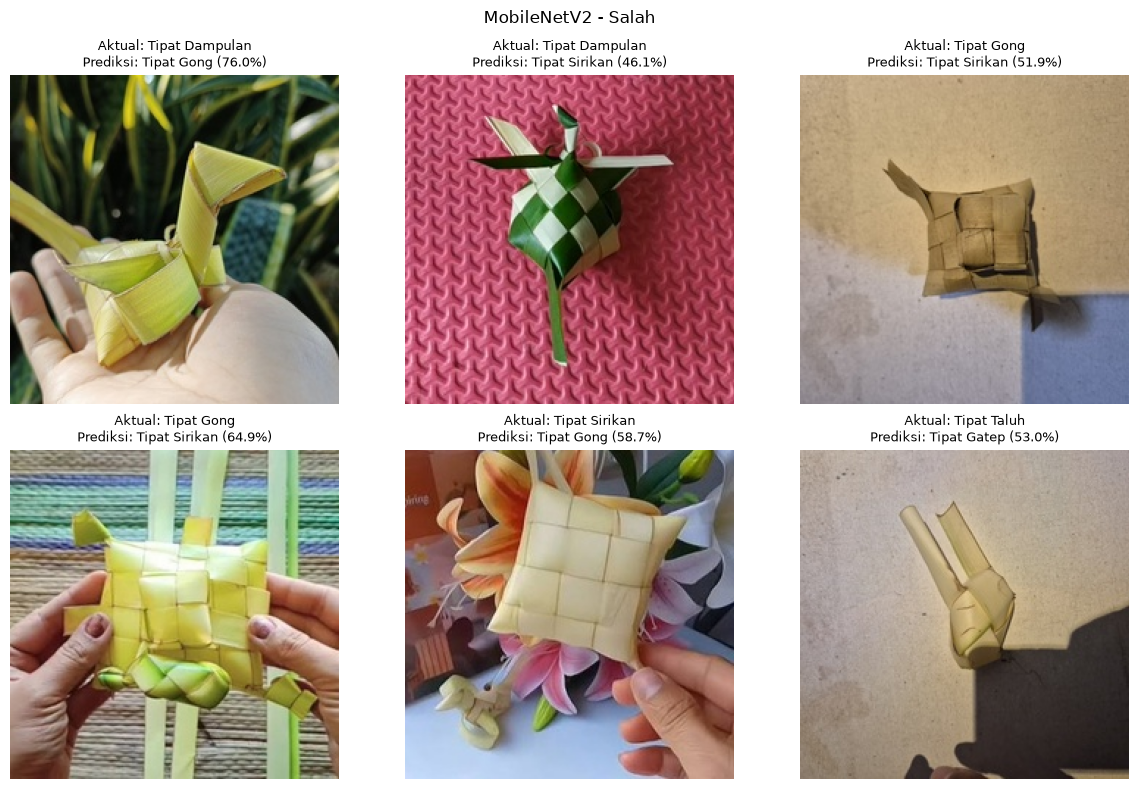

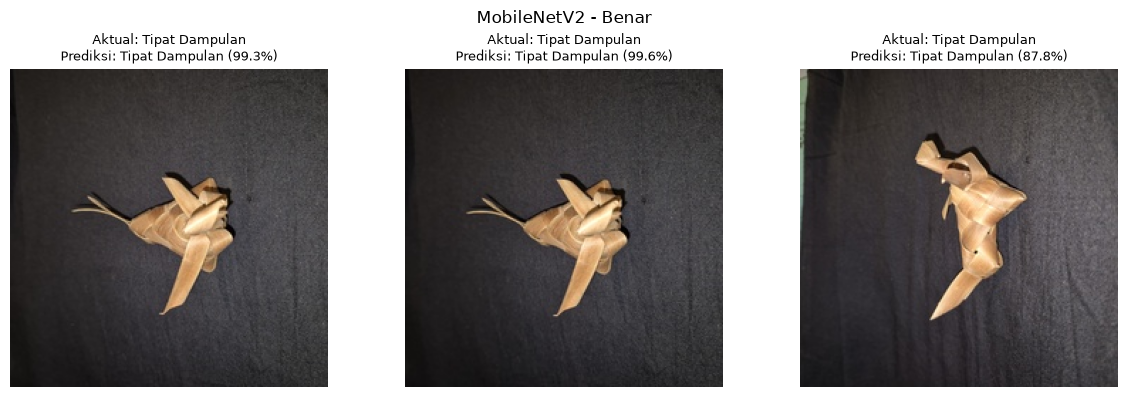

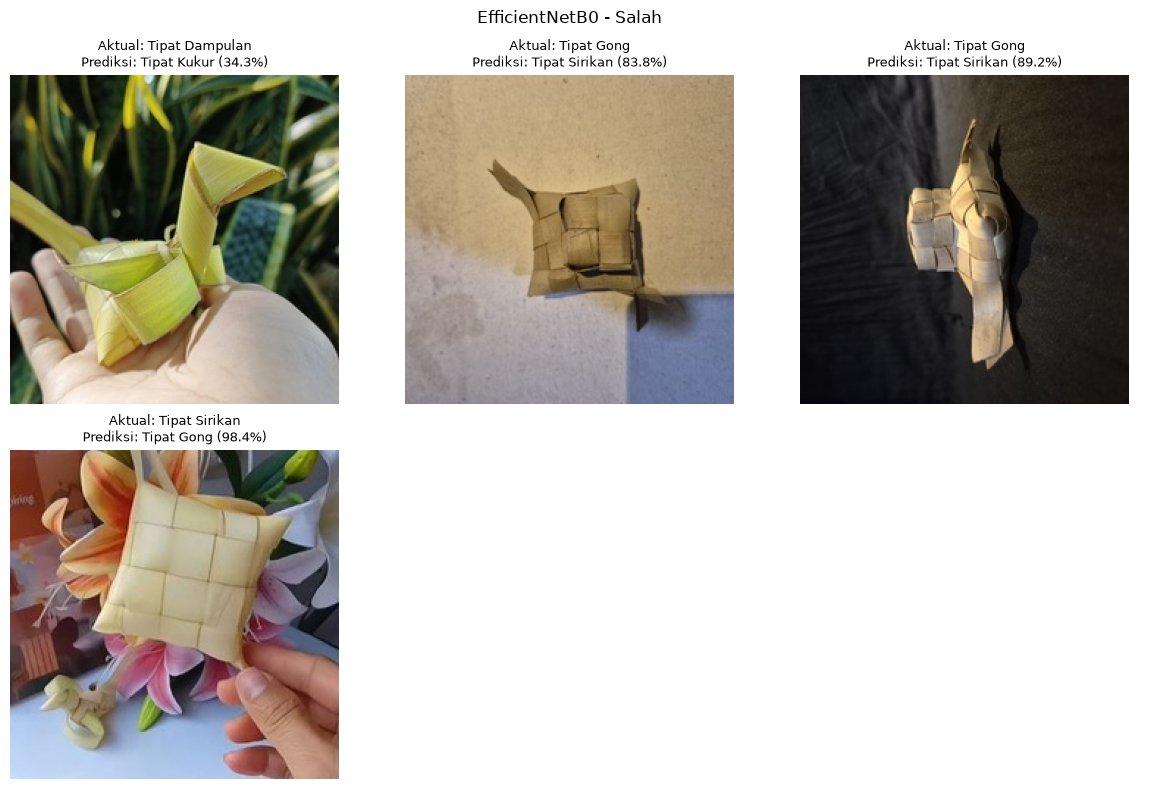

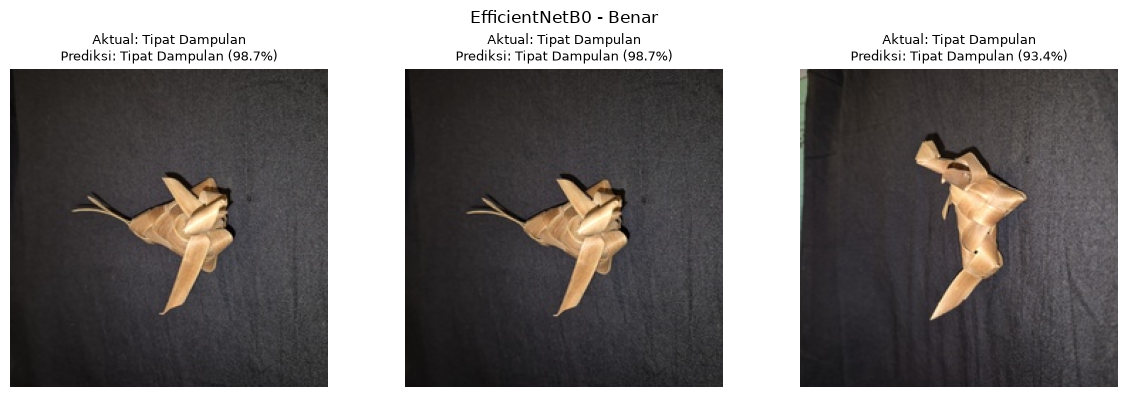

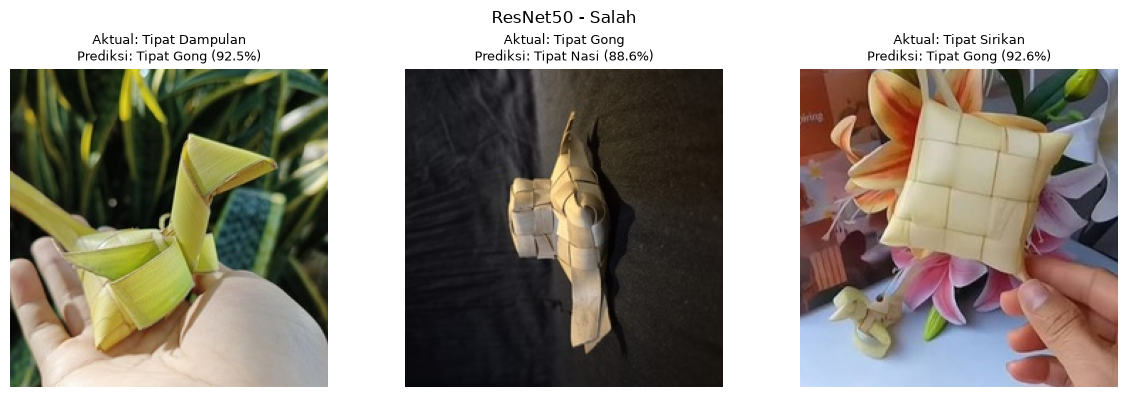

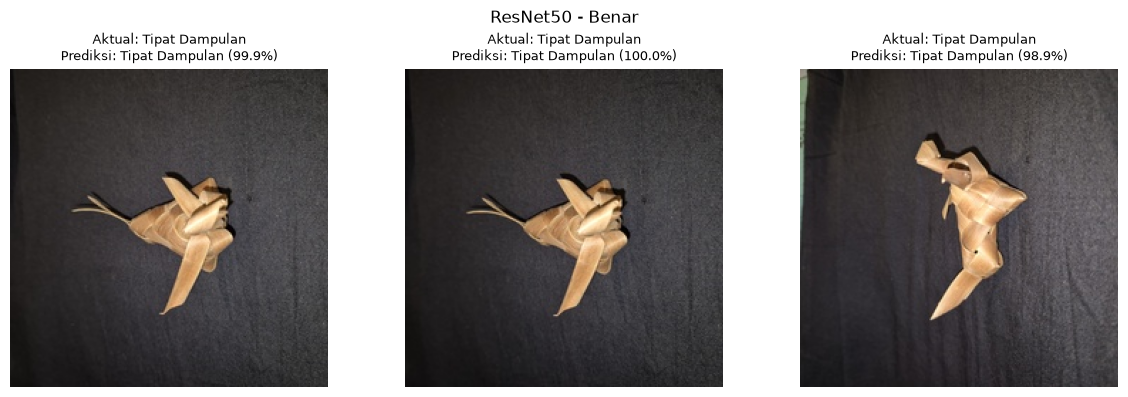

In [17]:
def show_examples(model_name, correct=False, n=6):
    examples = predictions_df[(predictions_df.Model == model_name) &
                              (predictions_df.Correct == correct)].head(n)
    if examples.empty:
        print(f"Tidak ada prediksi dengan Correct={correct} untuk {model_name}")
        return
    cols = min(3, len(examples))
    rows = int(np.ceil(len(examples) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, examples.iterrows()):
        with Image.open(r.filepath) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"Aktual: {r.Actual}\nPrediksi: {r.Predicted} ({r.Confidence:.1%})", fontsize=9)
    fig.suptitle(f"{model_name} - {'Benar' if correct else 'Salah'}")
    plt.tight_layout()
    plt.show()

for name in MODEL_NAMES:
    show_examples(name, correct=False, n=6)
    show_examples(name, correct=True, n=3)

# Selanjutnya, tuliskan secara manual dugaan penyebab kesalahan berdasarkan gambarnya.


## 3C. Pemeriksaan duplikat persis antar split

Cek hash file secara *byte-level*. Ini hanya mendeteksi file yang identik; foto berbeda dari objek yang sama atau gambar mirip perlu diperiksa lebih lanjut secara visual / menggunakan perceptual hashing.

In [18]:
def hash_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

hash_rows = []
for split in ["train", "validation", "test"]:
    paths, _ = image_files_and_labels(split)
    hash_rows.extend({"Split": split, "Path": str(p), "SHA256": hash_file(p)} for p in paths)
hashes = pd.DataFrame(hash_rows)
collisions = hashes.groupby("SHA256").filter(lambda g: g.Split.nunique() > 1)
print("Duplikat file identik lintas split:", collisions.SHA256.nunique() if not collisions.empty else 0)
display(collisions.sort_values("SHA256") if not collisions.empty else pd.DataFrame({"Info": ["Tidak ditemukan file identik lintas split"]}))
hashes.to_csv(STAGE34_DIR / "sha256_split.csv", index=False)


Duplikat file identik lintas split: 7


,Split,Path,SHA256
0,train,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,2ff9d8a493ab5573366393d9937acc25b2c418fe5ced0e...
405,validation,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,2ff9d8a493ab5573366393d9937acc25b2c418fe5ced0e...
7,train,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,317623d63c791f40a17df4e019c4e22785c018b80ed69d...
496,test,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,317623d63c791f40a17df4e019c4e22785c018b80ed69d...
11,train,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,4d52c527fb6a555be2660a089094e7e6af75cbe377c488...
497,test,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,4d52c527fb6a555be2660a089094e7e6af75cbe377c488...
406,validation,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,840454fe74ad1597b6e80475960452efd8db17f3903478...
494,test,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,840454fe74ad1597b6e80475960452efd8db17f3903478...
10,train,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,9438bacf2d2e4896896e86dffa5043b914501000520ff6...
408,validation,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,9438bacf2d2e4896896e86dffa5043b914501000520ff6...


## 3D. Bandingkan model transfer vs fine-tuned pada validation

Perbandingan dilakukan dengan *validation set*, bukan test set, sehingga kamu dapat menganalisis dampak fine-tuning tanpa menjadikan test set sebagai alat pemilihan berulang. File transfer dan fine-tuned harus tersedia untuk perbandingan ini.

,Model,Tahap,Val Accuracy,Val Loss,Val F1 Macro,Gambar Validasi
0,MobileNetV2,Transfer,0.8764,0.3131,0.8624,89
1,MobileNetV2,Fine-tuning,0.9326,0.2460,0.9278,89
2,EfficientNetB0,Transfer,0.9775,0.1484,0.9766,89
3,EfficientNetB0,Fine-tuning,0.9775,0.0712,0.9766,89
4,ResNet50,Transfer,0.9551,0.1384,0.9525,89
5,ResNet50,Fine-tuning,0.9663,0.1041,0.9653,89


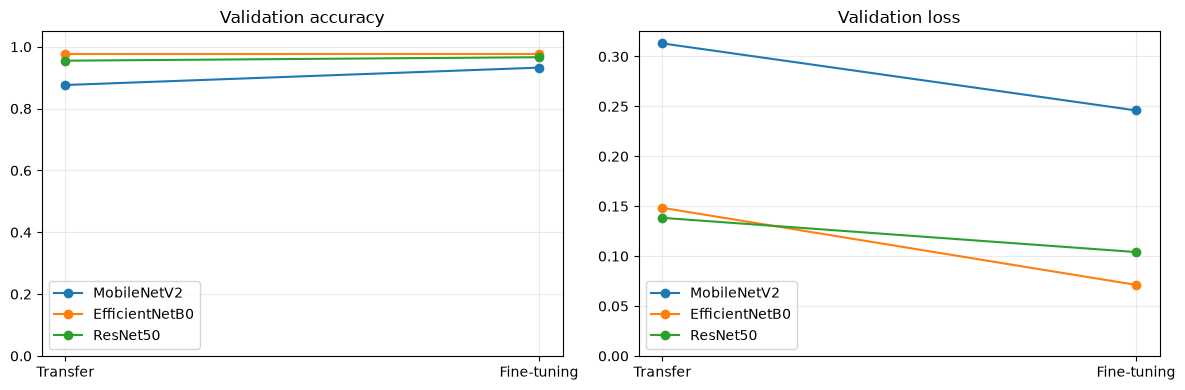

In [19]:
val_files, val_true = image_files_and_labels("validation")
validation_rows = []
for name in MODEL_NAMES:
    for stage, suffix in [("Transfer", "transfer"), ("Fine-tuning", "fine_tuned")]:
        path = MODEL_DIR / f"{name.lower()}_{suffix}.keras"
        if not path.is_file():
            print("Melewati file model yang tidak tersedia:", path)
            continue
        model = tf.keras.models.load_model(path, compile=False)
        prob = predict_files(model, val_files, name)
        preds = prob.argmax(axis=1)
        # Keras SparseCategoricalCrossentropy menerima probabilitas softmax.
        loss = float(tf.keras.losses.sparse_categorical_crossentropy(val_true, prob).numpy().mean())
        validation_rows.append({"Model": name, "Tahap": stage,
                                "Val Accuracy": accuracy_score(val_true, preds),
                                "Val Loss": loss,
                                "Val F1 Macro": f1_score(val_true, preds, average="macro", zero_division=0),
                                "Gambar Validasi": len(val_true)})
        del model
validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(STAGE34_DIR / "transfer_vs_finetuning_validation.csv", index=False)
display(validation_df.round(4))

if not validation_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for model_name in MODEL_NAMES:
        sub = validation_df[validation_df.Model == model_name]
        if not sub.empty:
            axes[0].plot(sub.Tahap, sub["Val Accuracy"], marker="o", label=model_name)
            axes[1].plot(sub.Tahap, sub["Val Loss"], marker="o", label=model_name)
    axes[0].set_title("Validation accuracy"); axes[0].set_ylim(0, 1.05)
    axes[1].set_title("Validation loss"); axes[1].set_ylim(bottom=0)
    for ax in axes:
        ax.legend(); ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(STAGE34_DIR / "perbandingan_transfer_finetuning.png", dpi=160)
    plt.show()

## 3E. Grafik training history (opsional)

Notebook awal memiliki variabel `histories` di RAM **tetapi belum menyimpannya ke disk**. Jika sesi notebook awal masih aktif, jalankan **kode ekspor ini di notebook awal** setelah eksperimen selesai:

```python
with open(RESULT_DIR / "training_histories.json", "w", encoding="utf-8") as f:
    json.dump(histories, f, indent=2)
```

Jika sesi sudah berakhir, grafik dari output notebook awal masih bisa dipakai dalam laporan; tidak perlu retraining hanya demi menyimpan JSON. Sel di bawah hanya membuat grafik baru jika JSON riwayat tersedia.

In [20]:
history_path = RESULT_DIR / "training_histories.json"
if history_path.is_file():
    histories_saved = json.loads(history_path.read_text(encoding="utf-8"))
    for name in MODEL_NAMES:
        if name not in histories_saved:
            continue
        h1 = histories_saved[name]["transfer"]
        h2 = histories_saved[name]["fine_tuning"]
        split = len(h1.get("loss", []))
        fig, axes = plt.subplots(1, 2, figsize=(13, 4))
        for ax, key, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
            for prefix, caption in [("", "Train"), ("val_", "Validation")]:
                y1, y2 = h1.get(prefix + key, []), h2.get(prefix + key, [])
                ax.plot(range(1, len(y1)+1), y1, label=caption)
                ax.plot(range(split+1, split+len(y2)+1), y2, label=f"{caption} fine-tuning", linestyle="--")
            ax.axvline(split+0.5, color="gray", linestyle=":", label="Awal fine-tuning")
            ax.set_title(f"{name} - {label}")
            ax.set_xlabel("Epoch gabungan"); ax.grid(alpha=.25); ax.legend(fontsize=8)
        plt.tight_layout()
        plt.savefig(STAGE34_DIR / f"history_{name}.png", dpi=160)
        plt.show()
else:
    print("training_histories.json belum ditemukan; grafik history baru dilewati, analisis lain tetap dapat dijalankan.")

training_histories.json belum ditemukan; grafik history baru dilewati, analisis lain tetap dapat dijalankan.


## 3F. Uji foto eksternal yang belum pernah digunakan (opsional tetapi dianjurkan)

Letakkan foto baru di `Foto_Tipat_Baru` pada direktori induk proyek. Jangan gunakan lagi foto dari dataset train/validation/test. Model tidak otomatis tahu label aslinya; jika ingin menghitung accuracy eksternal, kamu harus menyediakan label sebenarnya secara manual.

In [42]:
EXTERNAL_DIR = PROJECT_PARENT / "Foto_Tipat_Baru"
external_files = []
if EXTERNAL_DIR.is_dir():
    external_files = sorted(p for p in EXTERNAL_DIR.iterdir()
                            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if external_files:
    model = tf.keras.models.load_model(MODEL_DIR / "efficientnetb0_fine_tuned.keras", compile=False)
    probs = predict_files(model, external_files, "EfficientNetB0")
    ext_df = pd.DataFrame({
        "filepath": [str(p) for p in external_files],
        "prediksi": [class_names[i] for i in probs.argmax(axis=1)],
        "confidence": probs.max(axis=1),
        "label_sebenarnya_ISI_MANUAL": [""]*len(external_files)
    })
    ext_df.to_csv(STAGE34_DIR / "uji_foto_baru.csv", index=False)
    display(ext_df)
    del model
else:
    print(f"Belum ada foto baru pada {EXTERNAL_DIR}; bagian ini dilewati.")

,filepath,prediksi,confidence,label_sebenarnya_ISI_MANUAL
0,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,Tipat Dampulan,0.95803,


restnet

In [43]:

EXTERNAL_DIR = PROJECT_PARENT / "Foto_Tipat_Baru"

external_files = []
if EXTERNAL_DIR.is_dir():
    external_files = sorted(
        p for p in EXTERNAL_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    )

if external_files:
    model = tf.keras.models.load_model(
        MODEL_DIR / "resnet50_fine_tuned.keras",
        compile=False
    )

    probs = predict_files(model, external_files, "ResNet50")

    ext_df_resnet = pd.DataFrame({
        "filepath": [str(p) for p in external_files],
        "prediksi": [class_names[i] for i in probs.argmax(axis=1)],
        "confidence": probs.max(axis=1),
        "label_sebenarnya_ISI_MANUAL": [""] * len(external_files)
    })

    ext_df_resnet.to_csv(
        STAGE34_DIR / "uji_foto_baru_resnet50.csv",
        index=False
    )

    display(ext_df_resnet)
    del model

else:
    print(f"Belum ada foto baru pada {EXTERNAL_DIR}; bagian ini dilewati.")


,filepath,prediksi,confidence,label_sebenarnya_ISI_MANUAL
0,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,Tipat Dampulan,0.852841,


In [44]:

EXTERNAL_DIR = PROJECT_PARENT / "Foto_Tipat_Baru"

external_files = []
if EXTERNAL_DIR.is_dir():
    external_files = sorted(
        p for p in EXTERNAL_DIR.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
    )

if external_files:
    model = tf.keras.models.load_model(
        MODEL_DIR / "mobilenetv2_fine_tuned.keras",
        compile=False
    )

    probs = predict_files(model, external_files, "MobileNetV2")

    ext_df_mobile = pd.DataFrame({
        "filepath": [str(p) for p in external_files],
        "prediksi": [class_names[i] for i in probs.argmax(axis=1)],
        "confidence": probs.max(axis=1),
        "label_sebenarnya_ISI_MANUAL": [""] * len(external_files)
    })

    ext_df_mobile.to_csv(
        STAGE34_DIR / "uji_foto_baru_mobilenetv2.csv",
        index=False
    )

    display(ext_df_mobile)
    del model

else:
    print(f"Belum ada foto baru pada {EXTERNAL_DIR}; bagian ini dilewati.")


,filepath,prediksi,confidence,label_sebenarnya_ISI_MANUAL
0,C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP ...,Tipat Gong,0.824134,


# Tahap 4 — Finalisasi model

**Kandidat awal:** EfficientNetB0, berdasar perbandingan eksperimen yang sudah dibuat. Keputusan final tetap harus mempertimbangkan validasi, ukuran file, dan rencana penggunaan API. Jangan terus-menerus memilih ulang model berdasarkan test set.

## 4A. Tinjau perbandingan dan tentukan model

In [28]:
comparison_file = RESULT_DIR / "model_comparison_results.csv"
if comparison_file.is_file():
    comparison_df = pd.read_csv(comparison_file)
    display(comparison_df.round(4))
else:
    print("Ringkasan perbandingan tidak ditemukan; periksa notebook awal:", comparison_file)

# Model terpilih untuk contoh deployment lokal.
# Ganti jika hasil validasi tambahan menunjukkan pilihan lain yang lebih tepat.
SELECTED_MODEL = "EfficientNetB0"
print("Kandidat model final:", SELECTED_MODEL)

,Model,Training Time (seconds),Total Parameters,Trainable Parameters,Test Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,MobileNetV2,123.22,2270794,1523530,0.1853,0.9355,0.9493,0.9443,0.9448,0.9361
1,EfficientNetB0,253.06,4062381,1496170,0.1626,0.9570,0.9635,0.9652,0.9635,0.9569
2,ResNet50,489.89,23608202,14449162,0.1342,0.9462,0.9568,0.9548,0.9541,0.9466


Kandidat model final: EfficientNetB0


## 4B. Ekspor paket model untuk API dan periksa hasil inferensi

Simpan file model utuh, urutan label, dan metadata preprocessing. **Tidak ada normalisasi /255 tambahan untuk EfficientNetB0** karena model Keras EfficientNet sudah memasukkan penskalaan internal; gunakan fungsi preprocessing arsitektur yang sama seperti di notebook awal.

In [23]:
API_PACKAGE = PROJECT_PARENT / "Tipat_API_Package"
API_PACKAGE.mkdir(parents=True, exist_ok=True)
source_model = MODEL_DIR / f"{SELECTED_MODEL.lower()}_fine_tuned.keras"
export_model = API_PACKAGE / "tipat_model.keras"
shutil.copy2(source_model, export_model)
(API_PACKAGE / "class_names.json").write_text(
    json.dumps(class_names, indent=2, ensure_ascii=False), encoding="utf-8"
)
metadata = {
    "architecture": SELECTED_MODEL,
    "image_size": list(IMAGE_SIZE),
    "input_color_mode": "RGB",
    "input_dtype": "float32",
    "preprocessing": f"tf.keras.applications.{SELECTED_MODEL.lower()}.preprocess_input",
    "class_names_order": "Sama seperti class_names.json, indeks dimulai dari 0",
    "model_file": "tipat_model.keras",
    "notes": "Model telah mencakup classifier head, gunakan output softmax untuk kelas/confidence."
}
(API_PACKAGE / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)
loaded = tf.keras.models.load_model(export_model, compile=False)
check_file = test_files[0]
check_prob = predict_files(loaded, [check_file], SELECTED_MODEL)[0]
check_id = int(check_prob.argmax())
print("File ekspor:", export_model)
print("Ukuran file (MB):", round(export_model.stat().st_size / (1024**2), 2))
print("Sampel:", check_file.name)
print("Prediksi:", class_names[check_id], "| Confidence:", round(float(check_prob[check_id]), 4))
print("Jumlah probabilitas:", round(float(check_prob.sum()), 6))
assert len(check_prob) == len(class_names), "Jumlah output tidak sama dengan jumlah kelas"
assert np.isclose(check_prob.sum(), 1.0, atol=1e-4), "Output belum berupa probabilitas softmax valid"
del loaded


File ekspor: C:\Users\Ryan\Documents\JURNEY KAMPUS\S7\DEEP LEARNING\Tipat_API_Package\tipat_model.keras
Ukuran file (MB): 27.64
Sampel: 20261020_211947 - Copy.jpg
Prediksi: Tipat Dampulan | Confidence: 0.9873
Jumlah probabilitas: 1.0


## 4C. Checklist untuk masuk ke tahap 5 (API)

- [ ] Analisis foto benar dan salah telah diperiksa, beserta catatan kemungkinan penyebab error.
- [ ] Pemeriksaan duplikasi dan kemiripan data telah dilakukan.
- [ ] Perbandingan validation transfer vs fine-tuning telah dibuat.
- [ ] (Disarankan) Foto eksternal telah diuji dan dibahas keterbatasannya.
- [ ] Model `.keras` dapat di-*load* tanpa retraining.
- [ ] Urutan 10 kelas pada `class_names.json` sudah benar.
- [ ] Paket `Tipat_API_Package/` berisi `tipat_model.keras`, `class_names.json`, dan `metadata.json`.

**Setelah ini** barulah buat proyek FastAPI terpisah (`api/main.py`), kemudian uji dengan Postman. Jangan menaruh server API dalam notebook eksperimen agar struktur proyek lebih rapi.

**Catatan metodologis:** pemeriksaan SHA256 hanya mendeteksi duplikasi identik, bukan kebocoran dari foto objek yang sama. Training/validation/test yang dibuat sekali saja tidak mengestimasi variasi performa antar split. Tuliskan keterbatasan ini di laporan.